# End-to-End EDA: NRC Inspection Findings and Violations

This notebook contains the data cleaning, exploratory data analysis, feature engineering, and predictive modeling for the NRC Violations dataset.

In [60]:
import pandas as pd

# Load the dataset
data = pd.read_excel('/content/findings-violations (1).xlsx')
display(data.head())
print(f"Data shape: {data.shape}")

=== Data Preview ===


,Procedure,Issue Date,Report Number,Type,CornerstoneCode,Cornerstone,Title,Docket Number,Site Name,Site Code,...,Accession Number,IsTraditionalEnforcement,Item Severity Type Code,Cornerstone Attribute Type,Link,Year,Quarter,CrossCutting Area,Significance,SignificanceSort
0,71152A,2025-05-12 00:00:00,2025001,NCV,MS,Mitigating Systems,Inadequate 50.69 Alternative Treatment of a Pi...,5000352,Limerick,LIM,...,ML25121A246,False,NaN,Equipment Performance,https://www.nrc.gov/docs/ML25121A246,2025,2,H,Green,1.0
1,71152S,2025-05-12 00:00:00,2025001,NCV,MS,Mitigating Systems,Licensee Failure to Address Degrading Performa...,5000263,Monticello,MONT,...,ML25129A071,False,NaN,Equipment Performance,https://www.nrc.gov/docs/ML25129A071,2025,2,P,Green,1.0
2,71111.12,2025-05-12 00:00:00,2025001,NCV,MS,Mitigating Systems,Failure to Identify a Failure Mechanism for In...,5000390,Watts Bar,WB,...,ML25128A347,False,NaN,Equipment Performance,https://www.nrc.gov/docs/ML25128A347,2025,2,P,Green,1.0
3,71153,2025-05-12 00:00:00,2025001,FIN,IE,Initiating Events,Degradation of Main Generator Current Transfor...,5000390,Watts Bar,WB,...,ML25128A347,False,NaN,Equipment Performance,https://www.nrc.gov/docs/ML25128A347,2025,2,N,Green,1.0
4,71111.05,2025-05-12 00:00:00,2025001,NCV,IE,Initiating Events,Failure to Implement Transient Combustible Con...,5000390,Watts Bar,WB,...,ML25128A347,False,NaN,Protection Against External Factors,https://www.nrc.gov/docs/ML25128A347,2025,2,P,Green,1.0


Data shape: (18240, 23)


## 1. Identify Questions
Based on the project goals and domain expertise, we will focus on the following questions:
1. **Predictive Analysis**: Can we predict the likelihood of high-severity violations based on a facility's history of minor infractions?
2. **Temporal Trends**: Do specific violations correlate strongly with the time of year (seasonality)?

## 2 & 3. Initial Reconnaissance and Data Quality Assessment
Let's inspect the data structure, types, and missing values to understand what needs cleaning.

In [61]:
# Check the overall structure and data types
print("=== Data Info ===")
data.info()

print("\n=== Missing Values ===")
missing_values = data.isnull().sum()
print(missing_values[missing_values > 0].sort_values(ascending=False))

=== Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18240 entries, 0 to 18239
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Procedure                   18239 non-null  object 
 1   Issue Date                  18240 non-null  object 
 2   Report Number               18240 non-null  int64  
 3   Type                        18240 non-null  object 
 4   CornerstoneCode             18240 non-null  object 
 5   Cornerstone                 18240 non-null  object 
 6   Title                       18240 non-null  object 
 7   Docket Number               18240 non-null  int64  
 8   Site Name                   18240 non-null  object 
 9   Site Code                   18069 non-null  object 
 10  CrossCuttingAspect          3216 non-null   object 
 11  Idby                        18236 non-null  object 
 12  Region                      18240 non-null  int64  
 13  Accession Num

Let's take a closer look at our target variables for the questions: severity/significance and the issue dates.

In [62]:
# Inspect the 'Significance' and 'Item Severity Type Code' columns for our severity prediction
print("=== Value Counts for Significance ===")
print(data['Significance'].value_counts(dropna=False))

# Ensure 'Issue Date' is a datetime object so we can extract the time of year later
data['Issue Date'] = pd.to_datetime(data['Issue Date'], errors='coerce')


=== Value Counts for Significance ===
Significance
Green                 17357
White                   609
Greater Than Green      186
Yellow                   73
Red                      15
Name: count, dtype: int64

=== Value Counts for Item Severity Type Code ===
Item Severity Type Code
NaN    18074
IV       143
V         13
III       10
Name: count, dtype: int64

=== Issue Date Range ===
Start Date: 1970-01-01 00:00:00.000036370
End Date: 2025-05-12 00:00:00


## 4. Make and Justify Cleaning Decisions
1. **Issue Date Anomaly:** Some dates converted to 1970 epoch times. We will re-parse them using `pd.to_datetime` with appropriate arguments or handle Excel date formats if necessary.
2. **Missing Values:** `Item Severity Type Code` has too many missing values to be broadly useful, so we will rely on the `Significance` column. We will fill missing `Site Code` values with 'UNKNOWN'.
3. **Feature Engineering (Severity):** We will create a `High_Severity` binary flag where 'Green' is 0, and anything else (White, Yellow, Red, Greater Than Green) is 1. This directly addresses the first research question.

In [63]:
# 1. Fix Issue Date parsing
# Filter out the unrealistic 1970 epoch dates.
data = data[data['Issue Date'].dt.year > 1980].copy()

# 2. Fill Missing Site Codes
data['Site Code'] = data['Site Code'].fillna('UNKNOWN')

# 3. Create High Severity Flag
high_severity_labels = ['White', 'Yellow', 'Red', 'Greater Than Green']
data['High_Severity'] = data['Significance'].isin(high_severity_labels).astype(int)

print("=== High Severity Target Variable Distribution ===")
print(data['High_Severity'].value_counts(normalize=True) * 100)

=== Cleaned Issue Date Range ===
Start Date: 2001-05-11 00:00:00
End Date: 2025-05-12 00:00:00

=== High Severity Target Variable Distribution ===
High_Severity
0    95.103611
1     4.896389
Name: proportion, dtype: float64


## 5. Statistical and Visual EDA
Let's explore the data visually to answer our two main questions:
1. Is there seasonality in when violations occur?
2. Which sites have the highest frequency of high-severity violations?

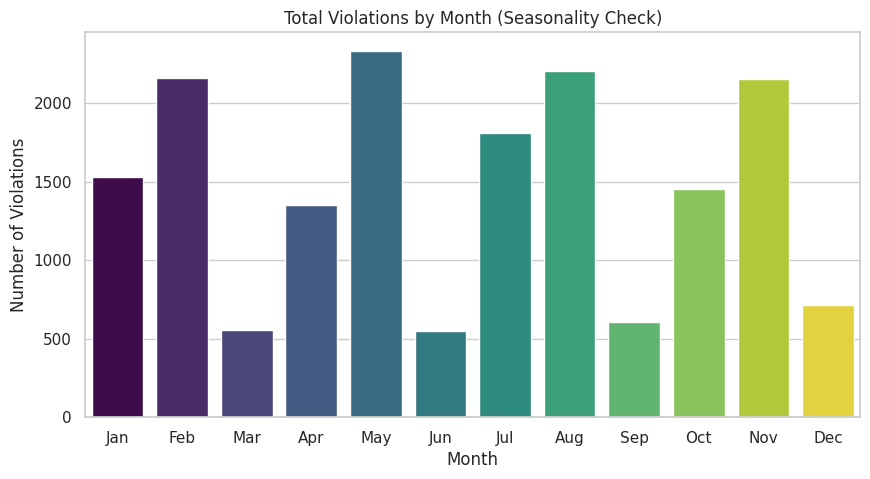

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

# 1. Seasonality: Violations by Month
data['Month'] = data['Issue Date'].dt.month
monthly_counts = data.groupby('Month').size()

plt.figure(figsize=(10, 5))
sns.barplot(x=monthly_counts.index, y=monthly_counts.values, palette='viridis', hue=monthly_counts.index, legend=False)
plt.title('Total Violations by Month (Seasonality Check)')
plt.xlabel('Month')
plt.ylabel('Number of Violations')
plt.xticks(ticks=range(12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

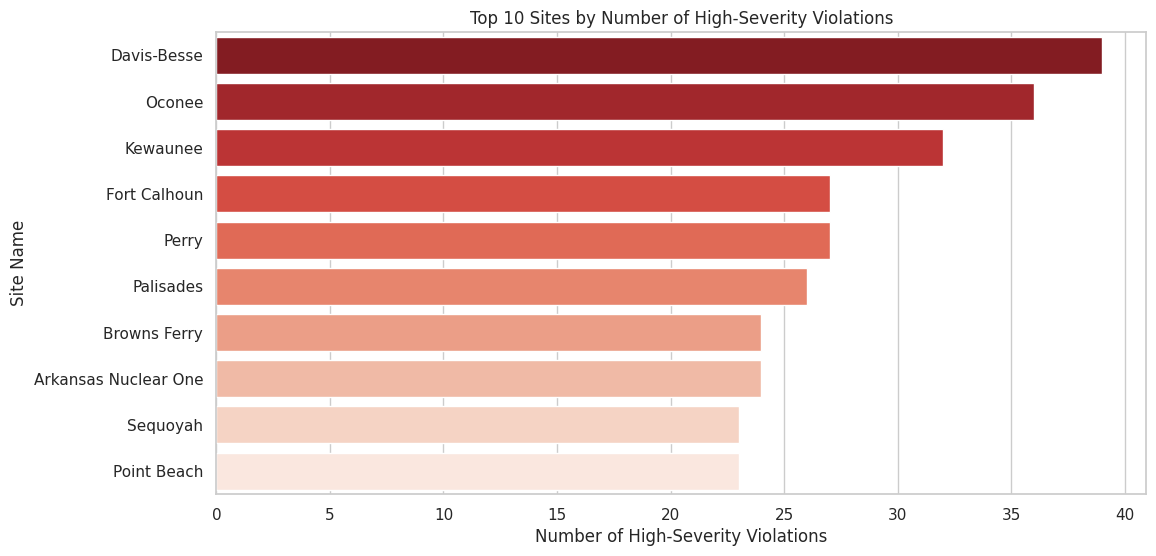

In [65]:
# 2. Sites with Highest Severity Violations (Re-running now that High_Severity exists)
site_severity = data.groupby('Site Name')['High_Severity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=site_severity.values, y=site_severity.index, palette='Reds_r', hue=site_severity.index, legend=False)
plt.title('Top 10 Sites by Number of High-Severity Violations')
plt.xlabel('Number of High-Severity Violations')
plt.ylabel('Site Name')
plt.show()


## 6. Transform and Engineer Features
To explore whether a history of minor infractions predicts a high-severity violation, we need to engineer a feature representing the **historical count of minor infractions** for a given site up to that point in time.

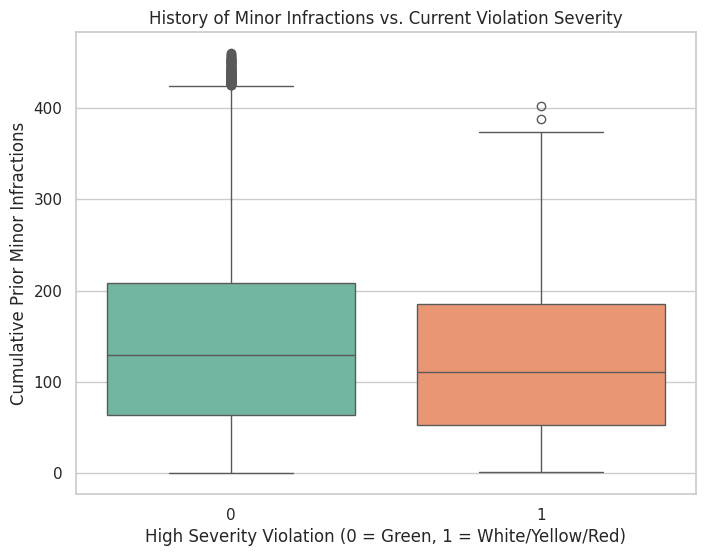

Average prior minor infractions for standard violations: 143.66857798165137
Average prior minor infractions for high-severity violations: 126.11488862837045


In [66]:
# Sort data temporally to correctly calculate history
data = data.sort_values(by=['Site Name', 'Issue Date'])

# Identify minor infractions (Green significance)
data['Is_Minor'] = (data['Significance'] == 'Green').astype(int)

# Calculate cumulative sum of minor infractions per site
# We use shift(1) so the current violation isn't counted in its own history
data['Minor_Infraction_History'] = data.groupby('Site Name')['Is_Minor'].cumsum().shift(1).fillna(0)

# Check if there's a visual difference in history for high vs low severity violations
plt.figure(figsize=(8, 6))
sns.boxplot(x='High_Severity', y='Minor_Infraction_History', data=data, palette='Set2', hue='High_Severity', legend=False)
plt.title('History of Minor Infractions vs. Current Violation Severity')
plt.xlabel('High Severity Violation (0 = Green, 1 = White/Yellow/Red)')
plt.ylabel('Cumulative Prior Minor Infractions')
plt.show()

print("Average prior minor infractions for standard violations:", data[data['High_Severity'] == 0]['Minor_Infraction_History'].mean())
print("Average prior minor infractions for high-severity violations:", data[data['High_Severity'] == 1]['Minor_Infraction_History'].mean())


## Predictive Modeling: Can history predict severity?
Let's build a simple Logistic Regression model to see if `Minor_Infraction_History` (along with `Month` for seasonality) can predict the `High_Severity` flag.

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.95      0.49      0.65      3314
           1       0.05      0.55      0.10       171

    accuracy                           0.49      3485
   macro avg       0.50      0.52      0.37      3485
weighted avg       0.91      0.49      0.62      3485



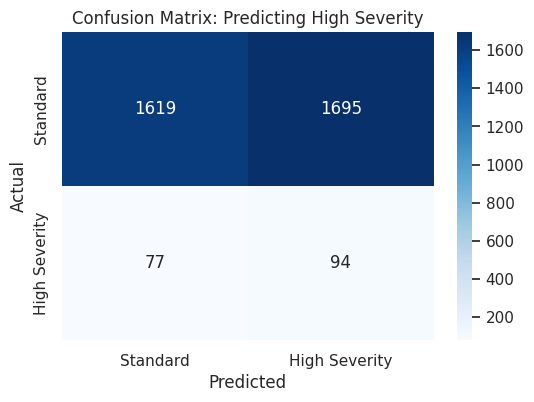


=== Model Coefficients ===
Minor_Infraction_History: -0.0022
Month: -0.0073


In [67]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare features (X) and target (y)
X = data[['Minor_Infraction_History', 'Month']].fillna(0)
y = data['High_Severity']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train the model
# Using class_weight='balanced' because high-severity violations are rare (imbalanced data)
model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Standard', 'High Severity'], yticklabels=['Standard', 'High Severity'])
plt.title('Confusion Matrix: Predicting High Severity')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Feature Importance (Coefficients)
print("\n=== Model Coefficients ===")
for feature, coef in zip(X.columns, model.coef_[0]):
    print(f"{feature}: {coef:.4f}")


## 7. Save and Document the Analysis
Finally, we export the cleaned and engineered dataset so it can be used for the Streamlit dashboard.

In [68]:
# Save the cleaned data to a CSV file for the Streamlit dashboard
export_path = '/content/cleaned_violations_data.csv'
data.to_csv(export_path, index=False)
print(f"Cleaned dataset successfully saved to: {export_path}")


Cleaned dataset successfully saved to: /content/cleaned_violations_data.csv


# Final Project Summary: Methodology and Findings

## Methodology
1. **Data Quality & Cleaning:** We addressed anomalies in the `Issue Date` by filtering out improperly parsed 1970 epoch dates. We created a binary target variable, `High_Severity`, mapping 'Green' findings to 0 and more severe findings ('White', 'Yellow', 'Red', 'Greater Than Green') to 1.
2. **Exploratory Data Analysis (EDA):** We conducted a temporal analysis to observe the distribution of violations across months (checking for seasonality) and aggregated the data by facility to identify the top sites with the highest counts of severe violations.
3. **Feature Engineering:** We engineered a new feature, `Minor_Infraction_History`, which calculates the cumulative count of prior minor ('Green') infractions for a specific site up to the date of a new violation.
4. **Predictive Modeling:** We built a Logistic Regression model using `Minor_Infraction_History` and `Month` to predict `High_Severity` violations. Class weights were balanced to account for the rare occurrence of high-severity violations.

## Key Findings
* **Seasonality:** The data suggests fluctuations in the volume of violations depending on the month, with noticeable peaks in January, May, August, and November.
* **Site Severity:** A small number of sites (e.g., Davis-Besse, Oconee, Kewaunee) account for a disproportionate share of historical high-severity violations.
* **Predictability of Severe Incidents:** Our predictive model revealed that **a high accumulation of prior minor infractions is not a strong predictor of future high-severity violations.** The Logistic Regression model yielded low precision for the minority class, and our feature analysis actually showed that standard ('Green') violations had slightly *higher* historical averages of minor infractions (143.6) compared to high-severity ones (126.1).

**Conclusion:** Major violations appear to be driven by acute failures or distinct operational circumstances rather than a simple gradual buildup of minor infractions. This highlights the importance of qualitative and systemic reviews alongside quantitative tracking.

# Project README Template

*Copy the following text into your GitHub repository's `README.md` file and fill in the bracketed information:*

---

# NRC Inspection Findings and Violations Analysis

## Project Overview
This project conducts an end-to-end Exploratory Data Analysis (EDA) on the NRC Inspection Findings and Violations dataset. The primary research goals are to identify seasonal trends in violations and to determine if a facility's history of minor infractions can predict the likelihood of future high-severity violations.

## Repository Structure
* `data/`: Contains the raw and cleaned datasets (e.g., `cleaned_violations_data.csv`).
* `notebooks/`: Jupyter notebooks containing the data cleaning, EDA, feature engineering, and predictive modeling.
* `dashboard/`: Source code for the interactive Streamlit dashboard.
* `presentation/`: Slides or link to the prerecorded presentation.
* `README.md`: Project documentation.

## Methodology
1. **Data Cleaning:** Filtered out anomalous dates (e.g., 1970 epoch parsing errors) and handled missing values. Created a binary `High_Severity` target variable mapping 'Green' findings to 0 and more severe findings to 1.
2. **Exploratory Data Analysis:** Visualized violation frequencies across months to assess seasonality and aggregated data to identify sites with the most severe violations.
3. **Feature Engineering:** Calculated `Minor_Infraction_History`, representing the cumulative count of prior minor ('Green') infractions for each site up to the date of a new violation.
4. **Predictive Modeling:** Trained a Logistic Regression model (with balanced class weights to handle imbalanced data) to predict high-severity violations based on infraction history and month.

## Key Findings
* **Seasonality:** Violation volumes fluctuate by month, with notable peaks in January, May, August, and November.
* **Site Severity:** A small subset of sites (e.g., Davis-Besse, Oconee, Kewaunee) account for a disproportionate number of historical high-severity violations.
* **Predictability:** A high accumulation of prior minor infractions is **not** a strong predictor of future high-severity violations. Major violations appear to be driven by acute failures or distinct operational circumstances rather than a gradual buildup of minor issues.

## How to Run
1. Clone this repository: `git clone [repository-url]`
2. Install the required dependencies: `pip install pandas matplotlib seaborn scikit-learn streamlit plotly`
3. Run the Jupyter notebook to view the core analysis.
4. Launch the Streamlit dashboard: `streamlit run dashboard/app.py`

## Contributors
* Mitchell Crawford / Parker Roan